# Projeto 1 — Inteligência Artificial
## Otimização de Rotas para Distribuição de Alimentos Locais

**Unidade Curricular:** Inteligência Artificial

**Ano Letivo:** 2026/2027

**Curso:** Engenharia de Sistemas Informáticos

**Grupo:** 18

**Elementos do grupo:**
- Guilherme Araujo 30146
- Rodrigo Lopes
- Tomas Gomes
- João Loureiro 31551

## 1. Resumo do Problema

O presente projeto, desenvolvido no âmbito da unidade curricular de Inteligência Artificial, tem como objetivo desenvolver um agente inteligente capaz de planear e otimizar rotas de recolha e distribuição de produtos alimentares locais.

O problema envolve produtores, clientes, centros de recolha e veículos de transporte. Os clientes realizam encomendas de produtos disponibilizados por diferentes produtores, sendo necessário determinar os percursos que os veículos devem realizar para recolher os produtos e entregá-los nos locais definidos.

O principal desafio consiste em encontrar rotas eficientes, procurando minimizar a distância total percorrida, respeitando simultaneamente um conjunto de restrições:

- **Janelas temporais:** os produtos devem ser recolhidos durante os períodos de disponibilidade dos produtores e entregues dentro dos horários estabelecidos.
- **Capacidade dos veículos:** a carga transportada não pode ultrapassar a capacidade máxima de cada veículo.
- **Ordem das operações:** a recolha dos produtos deve ocorrer antes da respetiva entrega.
- **Tempos de deslocação:** os percursos devem considerar as distâncias e os tempos de viagem entre as diferentes localizações.

Para resolver este problema, serão utilizadas diferentes técnicas de Inteligência Artificial, nomeadamente Greedy Best-First Search, A*, Hill Climbing e Constraint Satisfaction Problems (CSP).

Estas abordagens serão implementadas em Python e posteriormente avaliadas e comparadas, considerando a qualidade das soluções obtidas, os custos das rotas, os tempos de execução e o esforço computacional.

## 2. Análise Exploratória dos Dados (EDA)

Antes da implementação dos algoritmos, foi realizada uma análise exploratória do dataset `data_tiny`, disponibilizado para o projeto.

Esta análise permitiu compreender a organização dos dados, identificar as relações entre produtores, clientes, encomendas e veículos, e verificar a integridade dos dados necessários ao planeamento das rotas.

Foram identificados 5 produtores, 8 clientes, 10 encomendas, 23 artigos encomendados, 2 veículos, 1 centro de recolha e 6 locais de entrega.

A matriz de distâncias revelou-se completa e simétrica, contendo 132 ligações entre 12 localizações, sem valores em falta ou distâncias negativas.

A análise temporal permitiu ainda identificar 12 artigos cujas janelas de recolha terminam antes da criação da respetiva encomenda. Estas situações poderão representar restrições de inviabilidade que terão de ser consideradas na modelação do problema.

A análise completa, incluindo o código, os gráficos e as conclusões, encontra-se documentada num notebook independente.

**Notebook da EDA:** [Consultar Análise Exploratória dos Dados](https://colab.research.google.com/drive/12FWaIvBdJSoylMhv3waKl_61A0MqUpJT?usp=sharing)

Os resultados da EDA constituem a base para a modelação do problema e para a implementação dos algoritmos apresentados nas secções seguintes.


## 3. Abordagem e Modelação do Problema

### 3.1. Abordagem Geral

A resolução do problema será realizada através do desenvolvimento de um agente inteligente em Python, responsável por determinar rotas de recolha e entrega de produtos alimentares.

O agente utilizará as informações presentes no dataset, nomeadamente as localizações dos produtores, os locais de entrega, as características dos veículos, as encomendas e a matriz de distâncias e tempos de deslocação.

A abordagem proposta foi desenhada e estruturada de forma a testar e comparar **8 configurações distintas**, divididas em cinco grandes paradigmas de Inteligência Artificial:

- **Greedy Construtivo (Configurações 1 e 2):** Constrói rotas de forma incremental e direta, selecionando a próxima operação viável com base numa decisão puramente local, sem manter uma fronteira de estados alternativa para exploração.
- **Greedy Best-First Search (GBFS) (Configurações 3 e 4):** Uma pesquisa informada clássica que mantém uma fronteira de estados ativos numa fila de prioridades, ordenando os nós exclusivamente pela estimativa heurística $h(n)$ sem considerar o custo acumulado até ao momento. Isto permite retroceder e explorar caminhos alternativos caso a melhor opção imediata falhe.
- **A* (Configurações 5 e 6):** Pesquisa informada sistemática que orienta a exploração do espaço de estados utilizando a função de avaliação clássica $f(n) = g(n) + h(n)$, equilibrando o custo real acumulado $g(n)$ com a estimativa heurística $h(n)$ do percurso restante.
- **Satisfação de Restrições (CSP) (Configuração 7):** Modelação do problema através de variáveis de decisão, domínios de operações e restrições estritas (capacidade, precedência e janelas temporais), resolvida por uma pesquisa com retrocesso (*backtracking*).
- **Procura Local / Hill Climbing (Configuração 8):** Algoritmo de melhoria iterativa que toma uma solução completa inicial viável e explora a sua vizinhança na tentativa de reduzir a distância total percorrida.

### 3.2. Representação do Problema e Heurísticas

Para representar o problema serão utilizadas estruturas de dados que descrevem os principais elementos envolvidos no processo de distribuição:

- **Problem:** representa a instância global, incluindo encomendas, veículos, localizações e matriz de distâncias.
- **Request:** representa uma operação de recolha e entrega associada a um artigo encomendado.
- **Vehicle:** representa um veículo, incluindo a sua capacidade e o centro de recolha associado.
- **State:** representa o estado parcial de uma solução, incluindo a posição dos veículos, os produtos recolhidos e entregues, a carga transportada e o custo acumulado.

Esta representação permitirá aos algoritmos gerar novos estados, avaliar os custos das deslocações e verificar o cumprimento das restrições.

#### Heurísticas Desenvolvidas e Configurações de Pesquisa

Abaixo descrevem-se as heurísticas e critérios aplicados para cada uma das configurações estudadas:

##### 1. Greedy Construtivo (Heurística H1 e H2)
- **Funcionamento:** Executa uma escolha gulosa e local a cada passo a partir do estado atual, sem fila de prioridades ou gestão de fronteira global de procura. Se atingir um beco sem saída devido a restrições, o processo termina com uma solução incompleta.
  - **H1 (Menor Distância):** Seleciona a próxima recolha ou entrega viável que represente o menor acréscimo de distância física.
  - **H2 (Urgência Temporal):** Seleciona a próxima operação viável com a menor janela de tempo disponível (menor folga temporal entre a chegada prevista e o limite do cliente/produtor).

##### 2. Greedy Best-First Search (GBFS) (Heurística H1 e H2)
- **Funcionamento:** Mantém ativamente uma fronteira de estados expandidos organizada numa fila de prioridades, ordenando os nós estritamente pelo valor da heurística $h(n)$.
  - **H1 (Menor Distância):** A prioridade $h(n)$ estima o custo mínimo de deslocação imediata até à próxima tarefa válida.
  - **H2 (Urgência Temporal):** A prioridade $h(n)$ avalia a urgência com base na folga temporal disponível até à conclusão da próxima tarefa.
- Ao contrário do Greedy Construtivo, a GBFS regista o número de nós expandidos e consegue saltar para outros ramos da árvore de procura caso o ramo atual resulte numa violação de restrições operacionais.

##### 3. Algoritmo A* (Heurística H1 e H2)
- **Funcionamento:** Desenvolve a pesquisa orientada por $f(n) = g(n) + h(n)$:
  - **H1 (Heurística Nula):** $h(n) = 0$. O algoritmo comporta-se como uma pesquisa de custo uniforme, guiado estritamente por $g(n)$ (distância real percorrida).
  - **H2 (Estimativa de Distância Mínima):** $h(n)$ calcula a menor distância viável até à próxima operação de recolha ou entrega elegível.
- **Nota de Admissibilidade:** Devido à natureza dinâmica do problema de recolha e entrega com janelas temporais múltiplas e dois veículos, a heurística H2 funciona como um guia prático de exploração. Não existe demonstração matemática da sua admissibilidade formal, pelo que o A* é utilizado como um explorador sistemático de alta performance sem garantia matemática de otimalidade global absoluta.

### 3.3. Função de Custo

A função de custo terá como objetivo avaliar a distância total percorrida pelos veículos durante as operações de recolha e entrega.

A distância total será calculada através da soma das distâncias entre localizações consecutivas de cada rota.

A minimização desta função permitirá comparar as diferentes soluções viáveis e identificar os percursos mais eficientes. O custo total inclui as deslocações de regresso de todos os veículos ativos ao centro de recolha.

### 3.4. Restrições do Problema

Para garantir que as soluções produzidas pelos algoritmos são válidas, foram consideradas diferentes restrições operacionais.

**Capacidade dos veículos:** a carga transportada em cada momento não poderá ultrapassar a capacidade máxima de cada veículo, sendo necessário atualizar o peso transportado após cada recolha e entrega.

**Janelas temporais:** as recolhas deverão ocorrer dentro dos períodos de disponibilidade dos produtos e as entregas deverão respeitar os intervalos definidos pelos clientes.

**Precedência:** cada artigo terá de ser recolhido antes de poder ser entregue.

**Tempos de deslocação:** o planeamento deverá considerar os tempos necessários para viajar entre as diferentes localizações.

Adicionalmente, foi considerada a regra de que a recolha apenas poderá ocorrer após a criação da respetiva encomenda.

Durante a EDA foram identificados 12 artigos cuja janela de disponibilidade termina antes da criação da encomenda. De acordo com esta regra, estes artigos foram considerados inviáveis e excluídos dos testes iniciais de planeamento.

Deste modo, dos 23 artigos originais, 11 foram considerados para os testes de procura e otimização.

### Modelação por Satisfação de Restrições (CSP)

Para complementar a abordagem de pesquisa em espaço de estados, o problema foi formulado como um CSP (Constraint Satisfaction Problem), estruturado da seguinte forma:

- **Variáveis:** representam a atribuição de cada pedido de recolha e entrega a um veículo específico, bem como a definição da sequência e ordenação temporal destas operações.
- **Domínios:** o conjunto de operações viáveis que cada veículo pode executar em cada passo, tendo em conta a sua localização física atual e o estado temporal do sistema.
- **Restrições:** englobam o limite de capacidade máxima de cada veículo, a ordem de precedência obrigatória (recolha antes da respetiva entrega), o cumprimento estrito das janelas temporais de produtores e clientes, e a restrição de que cada artigo encomendado deve ser atribuído a exatamente um único veículo.
- **Resolução:** o CSP é solucionado utilizando um algoritmo de procura sistemática com *backtracking*, concebido para mapear as dependências e encontrar uma atribuição completa e viável que cumpra todas as restrições simultaneamente.

## 4. Apresentação do Código e Resultados

### 4.1. Organização da Implementação

A implementação do agente inteligente foi realizada em Python, utilizando um ficheiro independente para organizar as estruturas de dados e os algoritmos de resolução.

O código foi desenvolvido no Visual Studio Code e armazenado num repositório privado do GitHub, permitindo a colaboração entre os elementos do grupo.

Foram definidas estruturas para representar os veículos, os pedidos, os estados da procura e as informações necessárias para calcular as distâncias e os tempos de deslocação.

A implementação encontra-se organizada em componentes responsáveis pelo carregamento dos dados, validação das restrições, pesquisa de soluções e recolha de métricas de desempenho.

Os algoritmos implementados inicialmente foram Greedy Best-First Search e A*, tendo sido posteriormente realizados testes com Hill Climbing e CSP.

Numa fase seguinte, a pesquisa informada foi adaptada para considerar os dois veículos disponíveis no dataset.

### 4.2. Testes dos Algoritmos Greedy e A*

Numa fase inicial do desenvolvimento, foram realizados testes preliminares dos algoritmos de pesquisa, com o objetivo de verificar o funcionamento da representação dos estados, a geração de ações e a aplicação das restrições temporais e de capacidade.

Estes primeiros testes permitiram validar a sequência entre as operações de recolha e entrega, o cálculo das distâncias percorridas e a utilização de heurísticas para orientar a escolha das ações ou dos estados a explorar.

Foram consideradas duas abordagens distintas de pesquisa gulosa. A primeira corresponde ao **Greedy construtivo**, que seleciona sucessivamente a próxima operação válida de acordo com uma heurística, sem reconsiderar decisões anteriores. A segunda corresponde à **Greedy Best-First Search (GBFS)**, que mantém uma fronteira de estados organizada por prioridade heurística, permitindo explorar alternativas.

Foi igualmente implementado o algoritmo **A***, que combina o custo acumulado da rota com uma estimativa heurística do custo restante.

A implementação das diferentes abordagens permitiu verificar o efeito das heurísticas na ordem de exploração dos estados e no número de nós expandidos. No entanto, os testes preliminares não constituem a comparação experimental final, uma vez que esta foi posteriormente realizada com os dois veículos disponíveis e com cenários de complexidade crescente.

Os resultados finais dos algoritmos, incluindo as duas variantes heurísticas do Greedy construtivo, da GBFS e do A*, encontram-se apresentados e analisados nas secções 4.4, 4.5 e 5.

### 4.3. Testes com Dois Veículos

Após a validação inicial dos algoritmos, o problema foi alargado à utilização simultânea dos **dois veículos** disponibilizados no dataset `data_tiny`.

Nesta extensão, cada veículo passou a possuir o seu próprio estado, incluindo a localização atual, o instante temporal, a carga transportada e a sequência de operações realizadas. A solução global passou a ser constituída pelas rotas dos dois veículos, devendo garantir que cada artigo é recolhido e entregue pelo mesmo veículo e que não existem recolhas ou entregas duplicadas.

A geração de operações válidas considera a capacidade de transporte de cada veículo, as janelas temporais de recolha e entrega, os tempos de deslocação e a obrigatoriedade de recolher um artigo antes de o entregar. No final das rotas, é também contabilizado o regresso dos veículos ao respetivo centro de recolha.

Esta adaptação aumentou o espaço de estados, uma vez que cada operação pode envolver diferentes decisões de atribuição e ordenação entre os veículos. Consequentemente, tornou-se importante comparar não apenas a distância total percorrida, mas também a capacidade dos algoritmos para encontrar soluções completas e o esforço computacional necessário.

Para essa comparação, foram definidos três cenários experimentais, com **3, 5 e 11 artigos temporalmente elegíveis**, utilizando sempre a mesma frota de dois veículos.

A avaliação final contempla oito configurações: Greedy construtivo H1 e H2, GBFS H1 e H2, A* H1 e H2, CSP e Hill Climbing. Os resultados são apresentados na secção seguinte, permitindo analisar o comportamento das abordagens em cenários de complexidade crescente.

### 4.4. Execução dos Algoritmos no Google Colab

Nesta secção, são apresentados os testes dos algoritmos desenvolvidos em Python.

A implementação foi organizada em ficheiros Python independentes, permitindo separar a lógica dos algoritmos da apresentação e análise dos resultados.

Os testes utilizam o dataset `data_tiny` e permitem comparar a viabilidade das soluções, a distância total percorrida, os tempos de execução e o esforço de procura.

1. A CARREGAR O PROJETO DO GITHUB
✅ Projeto carregado do GitHub.

2. A CARREGAR O DATASET
✅ Dataset: /content/IA26_P01_G18/data_tiny
Ficheiros CSV: 11

3. A IMPORTAR OS ALGORITMOS
✅ Algoritmos importados.
Veículos: 2
Artigos elegíveis: 11

4. EXECUÇÃO EXPERIMENTAL

CENÁRIO: 3 ARTIGOS
Solução inicial Hill Climbing: GBFS H1


,cenario_artigos,algoritmo,viavel,distancia_km,nos_ou_passos,tempo_s,artigos_entregues,total_artigos,observacoes
0,3,Greedy construtivo H1,True,364.40,6,0.000693,3,3,
1,3,Greedy construtivo H2,False,288.71,6,0.000477,2,3,Sem próximas ações válidas; solução parcial
2,3,GBFS H1,True,395.19,52,0.009670,3,3,
3,3,GBFS H2,True,364.40,68,0.014348,3,3,
4,3,A* H1,True,364.40,113,0.007473,3,3,
5,3,A* H2,True,364.40,97,0.014079,3,3,
6,3,CSP,True,364.40,6,0.000486,3,3,backtracks=0
7,3,Hill Climbing,True,364.40,2,0.001442,3,3,



CENÁRIO: 5 ARTIGOS
Solução inicial Hill Climbing: GBFS H1


,cenario_artigos,algoritmo,viavel,distancia_km,nos_ou_passos,tempo_s,artigos_entregues,total_artigos,observacoes
0,5,Greedy construtivo H1,False,364.40,9,0.000988,3,5,Sem próximas ações válidas; solução parcial
1,5,Greedy construtivo H2,False,364.40,8,0.000880,3,5,Sem próximas ações válidas; solução parcial
2,5,GBFS H1,True,608.15,1162,0.402119,5,5,
3,5,GBFS H2,True,601.44,162,0.059126,5,5,
4,5,A* H1,True,577.36,3037,0.289131,5,5,
5,5,A* H2,True,577.36,2873,0.629318,5,5,
6,5,CSP,True,577.36,10,0.001154,5,5,backtracks=0
7,5,Hill Climbing,True,577.36,2,0.004314,5,5,



CENÁRIO: 11 ARTIGOS
Solução inicial Hill Climbing: CSP


,cenario_artigos,algoritmo,viavel,distancia_km,nos_ou_passos,tempo_s,artigos_entregues,total_artigos,observacoes
0,11,Greedy construtivo H1,False,328.14,15,0.003330,4,11,Sem próximas ações válidas; solução parcial
1,11,Greedy construtivo H2,False,259.99,6,0.001854,2,11,Sem próximas ações válidas; solução parcial
2,11,GBFS H1,False,254.18,2000,6.958189,1,11,Pesquisa sem solução completa (limite de expansões ou fronteira esgotada)
3,11,GBFS H2,False,829.56,2000,1.899278,8,11,Pesquisa sem solução completa (limite de expansões ou fronteira esgotada)
4,11,A* H1,False,100.09,2000,0.786055,2,11,Procura terminou sem solução completa (limite ou inviabilidade)
5,11,A* H2,False,100.09,2000,4.561096,2,11,Procura terminou sem solução completa (limite ou inviabilidade)
6,11,CSP,True,926.52,22,0.004845,11,11,backtracks=0
7,11,Hill Climbing,True,925.42,2,0.037515,11,11,



5. TABELA GERAL COMPARATIVA


,cenario_artigos,algoritmo,viavel,distancia_km,nos_ou_passos,tempo_s,artigos_entregues,total_artigos,observacoes
0,3,Greedy construtivo H1,True,364.40,6,0.000693,3,3,
1,3,Greedy construtivo H2,False,288.71,6,0.000477,2,3,Sem próximas ações válidas; solução parcial
2,3,GBFS H1,True,395.19,52,0.009670,3,3,
3,3,GBFS H2,True,364.40,68,0.014348,3,3,
4,3,A* H1,True,364.40,113,0.007473,3,3,
5,3,A* H2,True,364.40,97,0.014079,3,3,
6,3,CSP,True,364.40,6,0.000486,3,3,backtracks=0
7,3,Hill Climbing,True,364.40,2,0.001442,3,3,
8,5,Greedy construtivo H1,False,364.40,9,0.000988,3,5,Sem próximas ações válidas; solução parcial
9,5,Greedy construtivo H2,False,364.40,8,0.000880,3,5,Sem próximas ações válidas; solução parcial



6. GRÁFICO DAS ENTREGAS


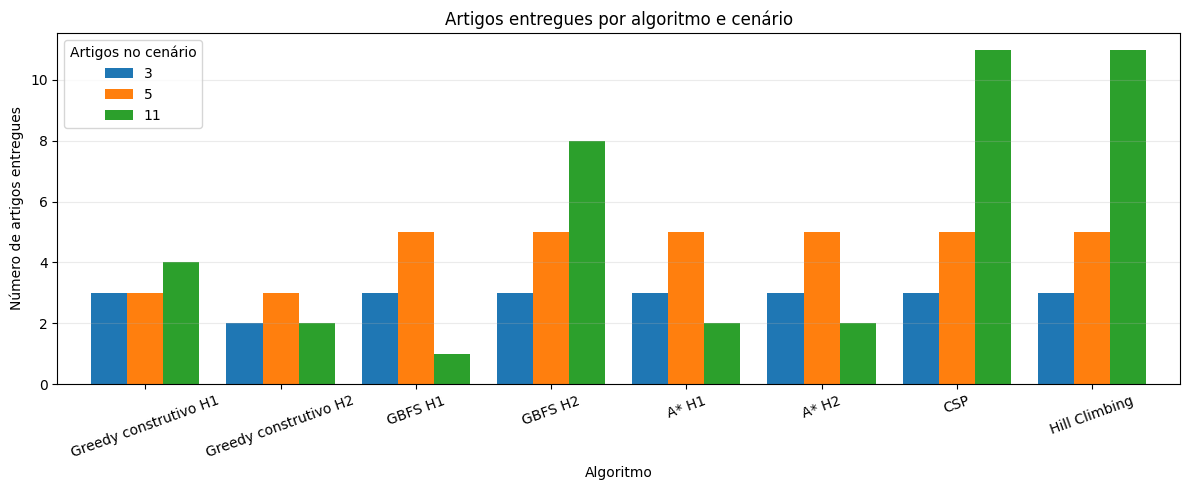


7. GRÁFICO DAS DISTÂNCIAS


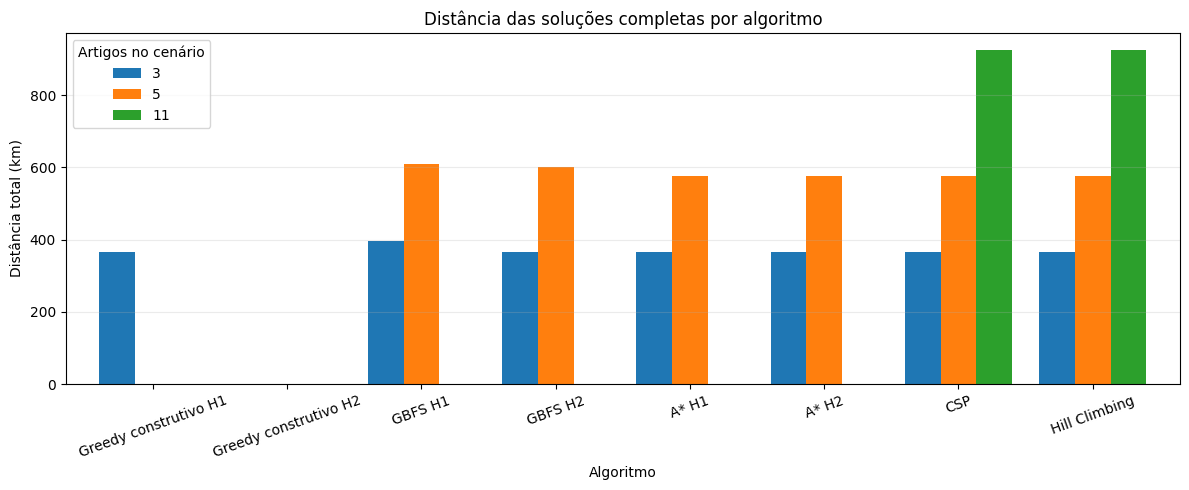


8. GRÁFICO DOS TEMPOS


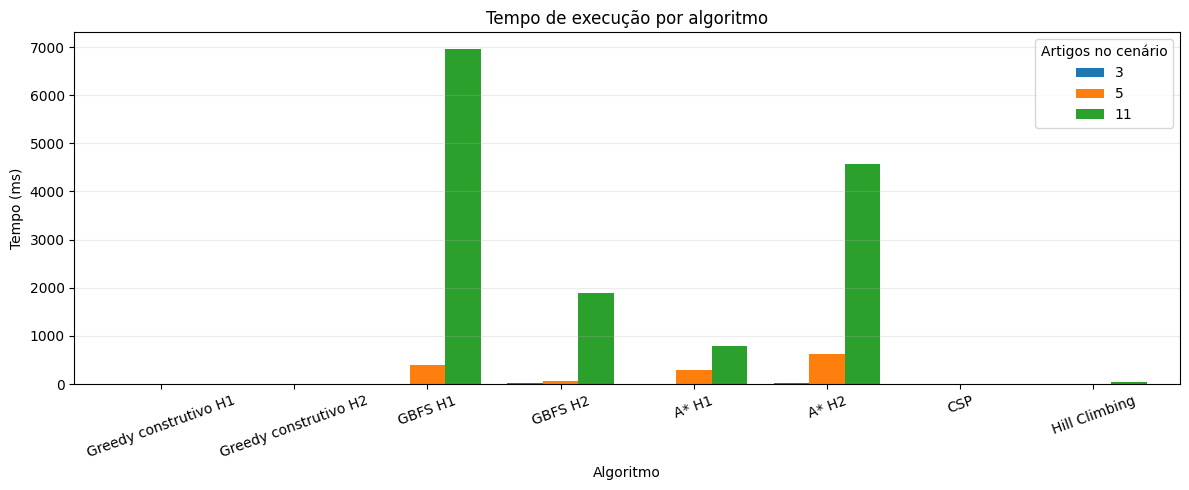


9. NÓS EXPANDIDOS E PASSOS


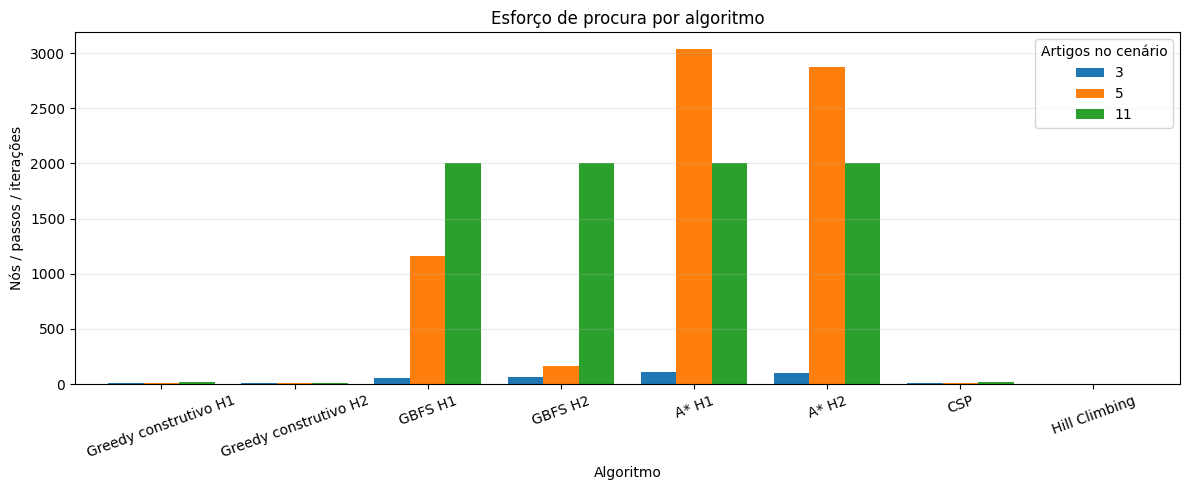

Nota: a métrica representa operações diferentes em cada algoritmo, não sendo diretamente equivalente.

10. EVOLUÇÃO DO HILL CLIMBING


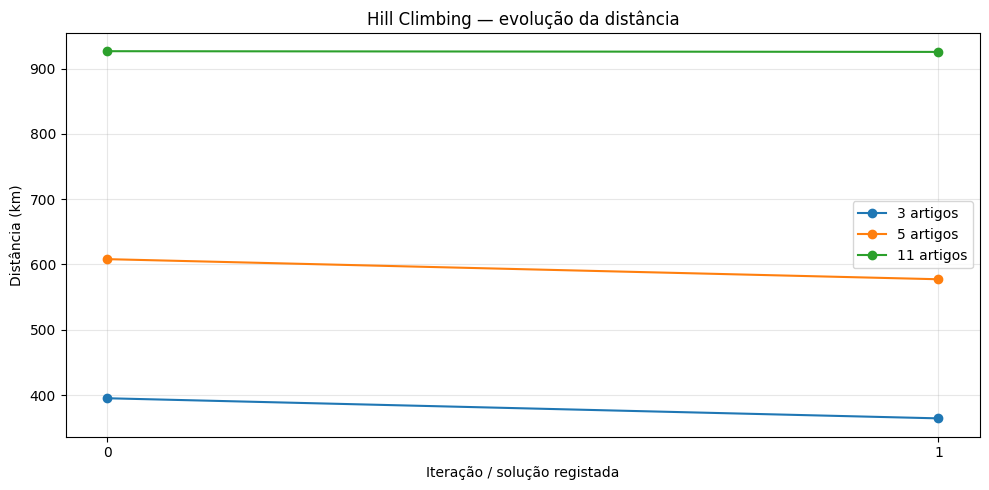

Uma linha horizontal significa que não houve melhoria registada da solução inicial.

11. RESUMO FINAL

CENÁRIO COM 3 ARTIGOS
Soluções completas: 7 de 8
Menor distância entre as soluções completas: Greedy construtivo H1 - 364.4 km

CENÁRIO COM 5 ARTIGOS
Soluções completas: 6 de 8
Menor distância entre as soluções completas: A* H1 - 577.36 km

CENÁRIO COM 11 ARTIGOS
Soluções completas: 2 de 8
Menor distância entre as soluções completas: Hill Climbing - 925.42 km

✅ ANÁLISE EXPERIMENTAL CONCLUÍDA!


In [ ]:

# ============================================================
# IA 2026/27 — PROJETO 1 — GRUPO 18
# Análise experimental: Greedy construtivo, GBFS, A*, Hill Climbing e CSP
# Cenários: 3, 5 e 11 artigos | 2 veículos
# ============================================================

import os
import sys
import math
import shutil
import zipfile
import tempfile
import subprocess
import importlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import files, userdata


# ============================================================
# 1. OBTER O CÓDIGO DO GITHUB
# ============================================================

REPO = "https://github.com/DevJoaoLoureiro/IA26_P01_G18.git"
PASTA_PROJETO = Path("/content/IA26_P01_G18")

print("=" * 60)
print("1. A CARREGAR O PROJETO DO GITHUB")
print("=" * 60)

# Token guardado nos Secrets do Colab
try:
    token = userdata.get("GITHUB_TOKEN")
except Exception:
    token = None

# Configuração do Git
env = os.environ.copy()
env["GIT_TERMINAL_PROMPT"] = "0"

with tempfile.TemporaryDirectory() as tmp:
    # Autenticação temporária para repositórios privados
    if token:
        helper = Path(tmp) / "askpass.sh"
        helper.write_text(
            '#!/bin/sh\n'
            'case "$1" in\n'
            '  *Username*) printf "%s\\n" "x-access-token" ;;\n'
            '  *Password*) printf "%s\\n" "$GITHUB_TOKEN" ;;\n'
            'esac\n'
        )
        helper.chmod(0o700)

        env["GITHUB_TOKEN"] = token
        env["GIT_ASKPASS"] = str(helper)

    # Clonar ou atualizar a versão existente
    if (PASTA_PROJETO / ".git").exists():
        subprocess.run(
            ["git", "-C", str(PASTA_PROJETO),
             "pull", "--ff-only"],
            env=env,
            check=True,
            capture_output=True,
            text=True
        )
    elif PASTA_PROJETO.exists():
        # Não apagar ficheiros já existentes
        raise RuntimeError(
            "A pasta do projeto já existe, mas não é um "
            "repositório Git. Verifica os ficheiros antes "
            "de a remover."
        )
    else:
        subprocess.run(
            ["git", "clone", REPO, str(PASTA_PROJETO)],
            env=env,
            check=True,
            capture_output=True,
            text=True
        )

print("✅ Projeto carregado do GitHub.")


# ============================================================
# 2. CARREGAR O DATASET
# ============================================================

print("\n" + "=" * 60)
print("2. A CARREGAR O DATASET")
print("=" * 60)

def localizar_dataset(raiz):
    """Encontrar uma pasta que contém os CSV necessários."""
    candidatos = [
        raiz / "data_tiny",
        raiz / "data",
        Path("/content/data_tiny"),
        Path("/content/data"),
    ]

    for pasta in candidatos:
        if (
            (pasta / "vehicles.csv").exists()
            and (pasta / "orders.csv").exists()
            and (pasta / "distance_matrix.csv").exists()
        ):
            return pasta

    return None


pasta_dados = localizar_dataset(PASTA_PROJETO)

if pasta_dados is None:
    print("Seleciona o ficheiro data_tiny.zip.")
    uploaded = files.upload()

    if "data_tiny.zip" not in uploaded:
        raise FileNotFoundError(
            "É necessário selecionar data_tiny.zip."
        )

    with zipfile.ZipFile(
        "/content/data_tiny.zip", "r"
    ) as z:
        # Recusar caminhos inseguros dentro do ZIP
        destino = PASTA_PROJETO.resolve()

        for ficheiro in z.infolist():
            caminho = (destino / ficheiro.filename).resolve()

            if not caminho.is_relative_to(destino):
                raise ValueError(
                    "O ZIP contém um caminho inseguro."
                )

        z.extractall(destino)

    pasta_dados = localizar_dataset(PASTA_PROJETO)

    # Algumas versões do ZIP guardam os CSV na raiz
    if pasta_dados is None:
        for candidato in PASTA_PROJETO.rglob("vehicles.csv"):
            pasta = candidato.parent

            if (
                (pasta / "orders.csv").exists()
                and (pasta / "distance_matrix.csv").exists()
            ):
                pasta_dados = pasta
                break

if pasta_dados is None:
    raise FileNotFoundError(
        "Não foi possível localizar os CSV do dataset."
    )

print("✅ Dataset:", pasta_dados)
print(
    "Ficheiros CSV:",
    len(list(pasta_dados.glob("*.csv")))
)


# ============================================================
# 3. IMPORTAR OS ALGORITMOS
# ============================================================

print("\n" + "=" * 60)
print("3. A IMPORTAR OS ALGORITMOS")
print("=" * 60)

sys.path.insert(0, str(PASTA_PROJETO))

import algoritmos
importlib.reload(algoritmos)


from algoritmos import (
    load_fleet_problem,
    fleet_greedy,         # Greedy construtivo
    fleet_gbfs,           # Greedy Best-First Search
    fleet_astar,          # A*
    fleet_hill_climbing,  # Hill Climbing
    fleet_csp,            # CSP
    fleet_summary
)


problema_completo = load_fleet_problem(str(pasta_dados))

print("✅ Algoritmos importados.")
print("Veículos:", len(problema_completo.vehicles))
print("Artigos elegíveis:", len(problema_completo.requests))


# ============================================================
# 4. EXECUTAR TODOS OS CENÁRIOS
# ============================================================

print("\n" + "=" * 60)
print("4. EXECUÇÃO EXPERIMENTAL")
print("=" * 60)

# Limites de procura para controlar o tempo de execução
LIMITE_GBFS = {
    3: 2000,
    5: 5000,
    11: 2000
}

LIMITE_ASTAR = {
    3: 2000,
    5: 5000,
    11: 2000
}

LIMITE_CSP = {
    3: 2000,
    5: 10000,
    11: 50000
}

todos_resultados = []
historicos_hill = {}
solucoes = {}

for n in [3, 5, 11]:

    print("\n" + "=" * 60)
    print(f"CENÁRIO: {n} ARTIGOS")
    print("=" * 60)

    # Recarregar para garantir testes independentes
    problema = load_fleet_problem(str(pasta_dados))

    # Selecionar os primeiros n artigos elegíveis
    problema.requests = problema.requests[:n]

    # --------------------------------------------------------
    # OITO CONFIGURAÇÕES: 2 GREEDY, 2 GBFS, 2 A*, CSP E HC
    # --------------------------------------------------------

    # Greedy construtivo: escolha local sem fronteira de pesquisa.
    gc1 = fleet_greedy(problema, heuristic_variant=1)
    gc2 = fleet_greedy(problema, heuristic_variant=2)

    # Greedy Best-First Search: prioridade h(n), com fronteira.
    gb1 = fleet_gbfs(problema, heuristic_variant=1,
                     max_expansions=LIMITE_GBFS[n])
    gb2 = fleet_gbfs(problema, heuristic_variant=2,
                     max_expansions=LIMITE_GBFS[n])

    # A*: prioridade g(n) + h(n).
    a1 = fleet_astar(problema, heuristic_variant=1,
                     max_expansions=LIMITE_ASTAR[n])
    a2 = fleet_astar(problema, heuristic_variant=2,
                     max_expansions=LIMITE_ASTAR[n])

    # CSP: primeira solução que satisfaz as restrições.
    csp = fleet_csp(problema, max_nodes=LIMITE_CSP[n])

    # Hill Climbing: primeiro uma solução completa da GBFS;
    # depois Greedy construtivo; por fim CSP (se necessário).
    alternativas = [
        ("GBFS H1", gb1),
        ("GBFS H2", gb2),
        ("Greedy construtivo H1", gc1),
        ("Greedy construtivo H2", gc2),
        ("CSP", csp),
    ]
    origem_hill, inicial = next(
        ((nome, r) for nome, r in alternativas if r.feasible),
        ("Sem solução inicial completa", None)
    )

    if inicial is not None:
        hill = fleet_hill_climbing(problema, inicial, max_iterations=100)
    else:
        # Mantém sempre as oito linhas das tabelas.
        hill = algoritmos.FleetResult(
            algorithm="fleet_hill_climbing", feasible=False,
            distance_km=float("inf"), expanded=0, runtime_s=0.0,
            routes={}, delivered=0, total=len(problema.requests),
            message="Sem solução inicial completa"
        )

    print("Solução inicial Hill Climbing:", origem_hill)

    historico = getattr(hill, "history", None)
    if historico:
        historicos_hill[n] = list(historico)

    nomes = [
        "Greedy construtivo H1", "Greedy construtivo H2",
        "GBFS H1", "GBFS H2", "A* H1", "A* H2",
        "CSP", "Hill Climbing"
    ]
    resultados_cenario = [gc1, gc2, gb1, gb2, a1, a2, csp, hill]
    tabela = fleet_summary(resultados_cenario)
    tabela["algoritmo"] = nomes
    tabela.insert(0, "cenario_artigos", n)
    todos_resultados.append(tabela)

    solucoes[n] = dict(zip(nomes, resultados_cenario))
    solucoes[n]["origem_hill"] = origem_hill

    display(
        tabela.style.format({
            "distancia_km": "{:.2f}",
            "tempo_s": "{:.6f}"
        })
    )


# ============================================================
# 5. TABELA GERAL COMPARATIVA
# ============================================================

print("\n" + "=" * 60)
print("5. TABELA GERAL COMPARATIVA")
print("=" * 60)

comparacao = pd.concat(
    todos_resultados,
    ignore_index=True
)

display(
    comparacao.style.format({
        "distancia_km": "{:.2f}",
        "tempo_s": "{:.6f}"
    })
)


# ============================================================
# 6. GRÁFICOS — ARTIGOS ENTREGUES
# ============================================================

print("\n" + "=" * 60)
print("6. GRÁFICO DAS ENTREGAS")
print("=" * 60)

plt.figure(figsize=(12, 5))

pivot_entregas = comparacao.pivot(
    index="algoritmo",
    columns="cenario_artigos",
    values="artigos_entregues"
)

ordem = [
    "Greedy construtivo H1", "Greedy construtivo H2",
    "GBFS H1", "GBFS H2", "A* H1", "A* H2",
    "CSP", "Hill Climbing"
]

pivot_entregas = pivot_entregas.reindex(ordem)

pivot_entregas.plot(
    kind="bar",
    ax=plt.gca(),
    width=0.8
)

plt.title("Artigos entregues por algoritmo e cenário")
plt.xlabel("Algoritmo")
plt.ylabel("Número de artigos entregues")
plt.xticks(rotation=20)
plt.legend(title="Artigos no cenário")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# 7. GRÁFICO — DISTÂNCIA DAS SOLUÇÕES COMPLETAS
# ============================================================

print("\n" + "=" * 60)
print("7. GRÁFICO DAS DISTÂNCIAS")
print("=" * 60)

# Comparar distâncias apenas quando a solução é completa.
# Distâncias de soluções parciais não são comparáveis
# com distâncias de soluções completas.

completas = comparacao[
    comparacao["viavel"] == True
].copy()

completas = completas[
    completas["distancia_km"].apply(math.isfinite)
]

if not completas.empty:

    pivot_distancias = completas.pivot(
        index="algoritmo",
        columns="cenario_artigos",
        values="distancia_km"
    )

    pivot_distancias = pivot_distancias.reindex(ordem)

    ax = pivot_distancias.plot(
        kind="bar",
        figsize=(12, 5),
        width=0.8
    )

    plt.title(
        "Distância das soluções completas por algoritmo"
    )
    plt.xlabel("Algoritmo")
    plt.ylabel("Distância total (km)")
    plt.xticks(rotation=20)
    plt.legend(title="Artigos no cenário")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

else:
    print("Nenhuma solução completa para representar.")


# ============================================================
# 8. GRÁFICO — TEMPO DE EXECUÇÃO
# ============================================================

print("\n" + "=" * 60)
print("8. GRÁFICO DOS TEMPOS")
print("=" * 60)

pivot_tempos = comparacao.pivot(
    index="algoritmo",
    columns="cenario_artigos",
    values="tempo_s"
)

pivot_tempos = pivot_tempos.reindex(ordem)

ax = (pivot_tempos * 1000).plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("Tempo de execução por algoritmo")
plt.xlabel("Algoritmo")
plt.ylabel("Tempo (ms)")
plt.xticks(rotation=20)
plt.legend(title="Artigos no cenário")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


# ============================================================
# 9. GRÁFICO — NÓS EXPANDIDOS / PASSOS
# ============================================================

print("\n" + "=" * 60)
print("9. NÓS EXPANDIDOS E PASSOS")
print("=" * 60)

pivot_nos = comparacao.pivot(
    index="algoritmo",
    columns="cenario_artigos",
    values="nos_ou_passos"
)

pivot_nos = pivot_nos.reindex(ordem)

pivot_nos.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("Esforço de procura por algoritmo")
plt.xlabel("Algoritmo")
plt.ylabel("Nós / passos / iterações")
plt.xticks(rotation=20)
plt.legend(title="Artigos no cenário")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Nota: a métrica representa operações diferentes "
    "em cada algoritmo, não sendo diretamente equivalente."
)


# ============================================================
# 10. HILL CLIMBING — CUSTO POR ITERAÇÃO
# ============================================================

print("\n" + "=" * 60)
print("10. EVOLUÇÃO DO HILL CLIMBING")
print("=" * 60)

if historicos_hill:

    plt.figure(figsize=(10, 5))

    for n, historico in historicos_hill.items():
        plt.plot(
            range(len(historico)),
            historico,
            marker="o",
            label=f"{n} artigos"
        )

    plt.title(
        "Hill Climbing — evolução da distância"
    )
    plt.xlabel("Iteração / solução registada")
    plt.ylabel("Distância (km)")
    plt.xticks(
        range(max(len(h) for h in historicos_hill.values()))
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(
        "Uma linha horizontal significa que não houve "
        "melhoria registada da solução inicial."
    )

else:
    print(
        "Não foi possível obter um histórico do "
        "Hill Climbing nestes cenários."
    )


# ============================================================
# 11. RESUMO FINAL AUTOMÁTICO
# ============================================================

print("\n" + "=" * 60)
print("11. RESUMO FINAL")
print("=" * 60)

for n in [3, 5, 11]:

    tabela_n = comparacao[
        comparacao["cenario_artigos"] == n
    ]

    completas_n = tabela_n[
        tabela_n["viavel"] == True
    ]

    print(f"\nCENÁRIO COM {n} ARTIGOS")

    print(
        "Soluções completas:",
        len(completas_n),
        "de",
        len(tabela_n)
    )

    if not completas_n.empty:

        melhor = completas_n.loc[
            completas_n["distancia_km"].idxmin()
        ]

        print(
            "Menor distância entre as soluções completas:",
            melhor["algoritmo"],
            "-",
            round(melhor["distancia_km"], 2),
            "km"
        )

    else:
        print("Nenhum algoritmo encontrou solução completa.")

print("\n✅ ANÁLISE EXPERIMENTAL CONCLUÍDA!")


### 4.5. Resultados Experimentais

A execução experimental foi realizada com o dataset `data_tiny`, considerando **dois veículos** e três cenários com **3, 5 e 11 artigos**. Foram avaliadas oito configurações algorítmicas: duas variantes do Greedy construtivo, duas variantes da Greedy Best-First Search (GBFS), duas variantes do A*, CSP e Hill Climbing.

A avaliação considerou o número de artigos entregues, a viabilidade das soluções, a distância total percorrida, o tempo de execução e o esforço computacional. Para as pesquisas GBFS e A* foram definidos limites de expansão, evitando uma exploração excessiva do espaço de estados.

#### Cenário de 3 artigos

Neste cenário, **sete das oito configurações** encontraram soluções completas. A única exceção foi o Greedy construtivo H2, que realizou apenas duas das três entregas.

O Greedy construtivo H1, a GBFS H2, ambas as variantes do A* e o CSP encontraram soluções completas com **364,40 km**. A GBFS H1 encontrou igualmente uma solução completa, mas com uma distância superior, de **395,19 km**.

No que diz respeito ao esforço de pesquisa, a GBFS H1 expandiu **52 nós**, enquanto a GBFS H2 expandiu **68 nós**. Para o A*, registaram-se **113 expansões na H1** e **97 na H2**.

O Hill Climbing foi inicializado com a solução da GBFS H1, de 395,19 km, e conseguiu reduzi-la para **364,40 km**, demonstrando a capacidade da pesquisa local para melhorar uma rota completa.

#### Cenário de 5 artigos

Com o aumento para cinco artigos, o Greedy construtivo H1 e H2 apenas conseguiram realizar **três das cinco entregas**, produzindo soluções parciais.

Em contrapartida, ambas as variantes da GBFS encontraram soluções completas. A GBFS H1 obteve **608,15 km**, após **1162 expansões**, enquanto a GBFS H2 obteve **601,44 km**, após **162 expansões**.

As variantes do A* encontraram soluções completas com **577,36 km**. A H1 expandiu **3037 nós** e a H2 expandiu **2873 nós**. O CSP também encontrou uma solução completa de 577,36 km, sem necessidade de backtracking.

O Hill Climbing foi inicializado com a solução da GBFS H1 e reduziu a distância de **608,15 km para 577,36 km**. Esta melhoria mostra a utilidade de combinar uma abordagem de pesquisa informada com um procedimento posterior de otimização local.

Neste cenário, **seis das oito configurações** encontraram soluções completas.

#### Cenário de 11 artigos

No cenário de maior dimensão, os algoritmos de pesquisa apresentaram maiores dificuldades em encontrar soluções completas dentro dos limites definidos.

O Greedy construtivo H1 realizou **4 das 11 entregas** e a H2 realizou apenas **2**. A GBFS H1 terminou com **1 artigo entregue**, enquanto a GBFS H2 conseguiu entregar **8 dos 11 artigos**, tendo ambas atingido o limite de **2000 expansões**.

As duas variantes do A* também atingiram o limite de 2000 expansões, terminando com **2 artigos entregues**. Estes resultados não demonstram a inexistência de soluções completas; indicam apenas que estas não foram encontradas dentro dos limites computacionais aplicados.

O CSP conseguiu encontrar uma solução válida para os **11 artigos**, com uma distância total de **926,52 km**, expandindo 22 nós e sem registar backtracking.

Como nenhuma das variantes do Greedy construtivo ou da GBFS encontrou uma solução completa neste cenário, o Hill Climbing foi inicializado com a solução do CSP. A pesquisa local permitiu reduzir a distância para **925,42 km**, mantendo todas as entregas e restrições satisfeitas.

Assim, apenas **duas das oito configurações**, CSP e Hill Climbing, apresentaram soluções completas neste cenário.

#### Síntese dos resultados

Os resultados demonstram que o Greedy construtivo apresenta tempos de execução muito reduzidos, mas pode terminar prematuramente em soluções parciais devido à natureza local das suas decisões.

A GBFS mostrou maior capacidade para explorar alternativas, conseguindo soluções completas nos cenários de 3 e 5 artigos. A heurística H2 da GBFS destacou-se no cenário de 5 artigos, encontrando uma solução de menor distância e com menos expansões do que a H1. No cenário de 11 artigos, a H2 também conseguiu completar mais entregas, embora sem encontrar uma solução globalmente viável dentro do limite estabelecido.

O A* encontrou soluções completas nos dois primeiros cenários, mas revelou maior exigência computacional à medida que aumentou o número de artigos. O CSP destacou-se por encontrar soluções completas nos três cenários, enquanto o Hill Climbing permitiu melhorar os custos das soluções iniciais.

Importa salientar que **as distâncias de soluções parciais não devem ser diretamente comparadas com as de soluções completas**, uma vez que não representam o mesmo número de entregas. Da mesma forma, o número de nós expandidos na pesquisa não é diretamente equivalente ao número de decisões construtivas, aos nós explorados pelo CSP ou às iterações de Hill Climbing.

A análise crítica destas diferenças é desenvolvida na secção seguinte.

## 5. Análise Final

A avaliação experimental permitiu comparar o comportamento de todos os algoritmos desenvolvidos nas suas 8 configurações na resolução do problema de otimização de rotas de recolha e distribuição de produtos alimentares locais.

### 5.1. Comparação dos Algoritmos

A análise dos dados demonstra de forma clara que a eficiência de um algoritmo de pesquisa não pode ser avaliada isoladamente pelo custo de distância obtido, mas sim pela sua robustez em satisfazer restrições operacionais complexas para fornecer soluções viáveis e completas.

- O **Greedy Construtivo** revelou-se a abordagem mais simples e computacionalmente mais rápida, mas a sua natureza míope resultou em caminhos parciais incompletos (apenas 3/5 entregas no cenário de 5 artigos, e no máximo 4/11 no cenário de 11 artigos), pois não dispõe de um mecanismo de retrocesso para reconsiderar escolhas locais anteriores.
- A introdução da **Greedy Best-First Search (GBFS)** clássica superou esta barreira nos cenários pequenos e intermédios. Ao gerir uma fila de prioridades baseada em $h(n)$, a GBFS conseguiu explorar ramos alternativos e encontrar soluções completas nos cenários de 3 e 5 artigos. Contudo, em cenários complexos (11 artigos), a ausência do custo real acumulado $g(n)$ na tomada de decisões conduziu a um esforço ineficiente que esgotou o limite de 2000 expansões.
- O **A*** demonstrou uma pesquisa robusta e sistemática, alcançando caminhos de elevada qualidade de custo (577,36 km) no cenário de 5 artigos. Todavia, devido à complexidade combinatória e ao crescimento exponencial do espaço de estados, atingiu o limite de expansões no cenário de 11 artigos.
- O **CSP** provou ser a abordagem mais estável e eficaz na obtenção de soluções completas em todos os três cenários estudados, demonstrando um tempo computacional de frações de segundo.
- O **Hill Climbing** evidenciou a utilidade de técnicas de melhoria de vizinhança local ao otimizar soluções de partida completas fornecidas pelos algoritmos de procura informada ou por restrições.


### 5.2. Influência das Heurísticas

A utilização de duas heurísticas em cada método de pesquisa permitiu observar a influência dos critérios de decisão nos resultados experimentais.

No **Greedy construtivo**, a heurística H1 privilegia a menor distância até à próxima operação válida, enquanto a H2 dá prioridade às operações com menor margem temporal. Nos testes realizados, a H1 apresentou um desempenho superior em termos de entregas concluídas. No cenário de 11 artigos, por exemplo, a heurística H1 conseguiu concluir **4 das 11 entregas**, enquanto a H2 concluiu apenas **2**.

Este comportamento evidencia uma limitação das decisões locais: uma escolha aparentemente vantajosa num determinado momento pode comprometer a realização de outras operações posteriormente, uma vez que o Greedy construtivo não reconsidera as decisões anteriores.

Na **Greedy Best-First Search (GBFS)**, a heurística H1 utiliza a menor distância até uma próxima operação válida como prioridade, enquanto a H2 considera a menor folga temporal. Ao contrário do Greedy construtivo, a GBFS mantém uma fronteira de estados e pode explorar diferentes sequências de operações.

No cenário de 3 artigos, a GBFS H1 encontrou uma solução de **395,19 km**, com **52 expansões**, enquanto a H2 encontrou uma solução de **364,40 km**, com **68 expansões**.

No cenário de 5 artigos, a H2 destacou-se: encontrou uma solução de **601,44 km com 162 expansões**, em comparação com os **608,15 km e 1162 expansões** da H1. Neste caso, a utilização da folga temporal permitiu orientar a pesquisa de forma mais eficaz.

No cenário de 11 artigos, ambas as variantes atingiram o limite de **2000 expansões**, mas a H2 conseguiu concluir **8 das 11 entregas**, contra apenas **1 entrega** da H1. Embora nenhuma tenha encontrado uma solução completa, esta diferença indica que a heurística temporal foi mais eficaz na obtenção de progresso parcial nesta instância.

No **A***, a H1 utiliza uma heurística nula, `h(n) = 0`, enquanto a H2 considera a menor distância até uma próxima operação válida. O algoritmo organiza a pesquisa através da função `f(n) = g(n) + h(n)`.

Nos cenários de 3 e 5 artigos, a H2 expandiu menos nós do que a H1: **97 contra 113** e **2873 contra 3037**, respetivamente. Contudo, apresentou tempos de execução superiores nas medições realizadas, devido ao custo adicional do cálculo heurístico.

Assim, os resultados demonstram que uma heurística pode reduzir a quantidade de estados explorados sem reduzir necessariamente o tempo total de execução. Importa também salientar que a admissibilidade da heurística H2 do A* não foi demonstrada, pelo que não é possível garantir a otimalidade global das soluções obtidas.

### 5.3. Análise do Hill Climbing

Por ser uma abordagem de melhoria local de gradiente, o Hill Climbing exige obrigatoriamente a inicialização a partir de uma solução perfeitamente viável e completa:

- **No cenário de 3 artigos:** O algoritmo foi inicializado com a solução gerada pelo **GBFS H1** (395,19 km), conseguindo reduzi-la significativamente para **364,40 km** (uma melhoria de **30,79 km**, aproximadamente **7,79%** em apenas duas iterações).
- **No cenário de 5 artigos:** Utilizou-se igualmente a solução de partida do **GBFS H1** (608,15 km). O Hill Climbing reduziu a distância percorrida para **577,36 km** (uma redução de **30,79 km**, equivalente a **5,06%** de ganho de eficiência).
- **No cenário de 11 artigos:** Visto que nenhuma das configurações gulosas (Greedy ou GBFS) conseguiu encontrar uma solução completa viável, o Hill Climbing foi inicializado utilizando a rota viável do **CSP** (926,52 km). Através de trocas de vizinhança local, conseguiu refiná-la para **925,42 km** (ganho de **1,10 km**, cerca de **0,12%**).

Estes resultados demonstram que a qualidade do Hill Climbing é fortemente influenciada pela solução inicial. Além disso, por realizar trocas discretas numa vizinhança limitada, o algoritmo pode ficar retido em ótimos locais.

### 5.4. Análise do CSP

A abordagem **Constraint Satisfaction Problem (CSP)** foi utilizada para encontrar soluções que respeitassem simultaneamente as restrições de capacidade dos veículos, precedência entre recolha e entrega, janelas temporais e atribuição dos artigos aos veículos.

Ao contrário das abordagens que privilegiam diretamente a exploração heurística dos estados, o CSP procura uma atribuição e uma sequência de operações que satisfaçam todas as condições impostas pelo problema.

Nos três cenários experimentais, o CSP encontrou soluções completas:

- **3 artigos:** 364,40 km;
- **5 artigos:** 577,36 km;
- **11 artigos:** 926,52 km.

Nas execuções registadas, o algoritmo não necessitou de realizar backtracking. **Este resultado indica que, para as instâncias testadas, a ordem de exploração das ações válidas permitiu encontrar soluções completas sem necessidade de retroceder a decisões anteriores.**

É importante, contudo, distinguir a obtenção de uma solução viável da minimização da distância. A implementação do CSP procura uma primeira solução que respeite as restrições, não garantindo que essa solução apresente o menor custo possível.

Esta diferença ficou evidente no cenário de 11 artigos, em que o Hill Climbing conseguiu melhorar a solução encontrada pelo CSP, reduzindo a distância de **926,52 km para 925,42 km**.

Desta forma, a combinação entre satisfação de restrições e otimização local revelou-se uma estratégia eficaz para encontrar e melhorar soluções completas nesta instância experimental.

### 5.5. Limitações e Discussão

- **Natureza dos Dados:** Os ensaios foram realizados no dataset sintético `data_tiny`, que inclui apenas 2 veículos de características fixas e um número restrito de localizações. O desempenho dos algoritmos pode variar ao lidar com instâncias operacionais reais de grande dimensão.
- **Limites Computacionais:** A aplicação de tetos arbitrários de exploração de nós (como o limite de 2000 expansões no A* e na GBFS) impede a exploração completa do espaço de estados.
- **Sensibilidade do Ambiente:** Os tempos de computação medidos decorrem de execuções únicas e dependem da infraestrutura partilhada da plataforma Google Colab, não devendo ser tomados como medidas absolutas.
- **Divergência de Métricas:** Devem distinguir-se de forma clara as métricas de esforço (nós expandidos no A*/GBFS, passos no Greedy, nós processados no CSP e iterações de melhoria no Hill Climbing), uma vez que não são numericamente equivalentes.
- **Exclusão de Artigos:** Dos 23 artigos originais, 12 foram excluídos devido à regra temporal adotada de que a recolha de um produto só pode iniciar-se após a emissão da respetiva encomenda. Isto limita o âmbito da otimização aos 11 artigos elegíveis.
- **Falta de Demonstração de Otimização:** Devido aos limites de pesquisa aplicados e às simplificações adotadas, as rotas apresentadas não constituem uma prova matemática de otimalidade global absoluta.

## 6. Conclusão

O presente projeto teve como objetivo desenvolver um agente de Inteligência Artificial capaz de planear e otimizar rotas de recolha e distribuição de produtos alimentares locais. Para esse efeito, foi considerado um problema de recolha e entrega com dois veículos, no qual era necessário minimizar a distância total percorrida, respeitando simultaneamente as restrições de capacidade, precedência entre operações e janelas temporais.

Ao longo do desenvolvimento, foi realizada uma análise exploratória dos dados, definida uma representação do problema e implementadas diferentes abordagens de pesquisa e otimização: **Greedy construtivo, Greedy Best-First Search (GBFS), A*, Hill Climbing e Constraint Satisfaction Problem (CSP)**. A utilização de duas heurísticas para as abordagens Greedy e A* permitiu analisar de que forma diferentes critérios influenciam a exploração dos estados e os resultados obtidos.

A avaliação experimental, realizada com cenários de 3, 5 e 11 artigos, demonstrou que as abordagens apresentam vantagens e limitações distintas. O Greedy construtivo destacou-se pela rapidez, mas revelou dificuldades em construir soluções completas. A GBFS permitiu explorar alternativas e encontrar soluções completas nos cenários de 3 e 5 artigos, enquanto o A* também conseguiu resolver integralmente esses dois cenários. O CSP encontrou soluções completas nos três cenários, incluindo o de 11 artigos, no qual as restantes abordagens de construção de soluções não conseguiram concluir todas as entregas dentro dos limites definidos.

A aplicação do **Hill Climbing** demonstrou a importância da otimização local após a obtenção de uma solução válida. Partindo de soluções da GBFS H1, foi possível reduzir a distância de 395,19 km para 364,40 km no cenário de 3 artigos e de 608,15 km para 577,36 km no cenário de 5 artigos. No cenário de 11 artigos, o Hill Climbing foi inicializado com a solução do CSP, reduzindo a distância de 926,52 km para **925,42 km**, mantendo todas as entregas e restrições satisfeitas.

Apesar dos resultados obtidos, o estudo apresenta limitações associadas à dimensão reduzida do dataset, à utilização de limites computacionais e à ausência de garantias de otimalidade global. Como trabalho futuro, seria relevante desenvolver heurísticas mais informativas, introduzir estratégias de poda e redução do espaço de estados, melhorar os mecanismos de pesquisa local e avaliar o comportamento do agente em datasets maiores e mais próximos de situações reais. Ainda assim, o projeto permitiu aplicar e comparar diferentes técnicas de Inteligência Artificial num problema concreto de planeamento logístico, evidenciando as vantagens da sua utilização complementar.